In [77]:
import numpy as np
import math
import json
import statistics
from pathlib import Path
from matplotlib import pyplot as plt
%matplotlib inline

In [82]:
meas = {}
for f in Path('../data').glob('*.json'):
    d = json.loads(f.read_bytes())
    d['adc1'] = np.array(d['adc1'])
    d['adc2'] = np.array(d['adc2'])
    d['var1'] = np.array(d['var1'])
    d['var2'] = np.array(d['var2'])
    meas[d['meta']] = d

for n in sorted(meas):
    print(n)

74lvc_mesh_new_p0.3mm
74lvc_mesh_new_p0.4mm
74lvc_mesh_new_p0.6mm
74lvc_mesh_new_p1.0mm
74lvc_mesh_p0.3mm
74lvc_mesh_p0.3mm_flip
74lvc_mesh_p0.3mm_term
74lvc_mesh_p0.4mm
74lvc_mesh_p0.6mm
74lvc_mesh_p1.0mm
74lvc_new_mesh_p0.3mm
74lvc_new_mesh_p0.3mm_flip
74lvc_new_mesh_p0.3mm_term
74lvc_new_open
74lvc_open
max3748_mesh_0.3mm
max3748_mesh_0.3mm_flip
max3748_mesh_0.3mm_term
max3748_mesh_0.4mm
max3748_mesh_0.6mm
max3748_mesh_1.0mm
max3748_open
pi3hdx_clipline_offset_a_mesh_p0.3mm
pi3hdx_clipline_offset_a_mesh_p0.3mm_flip
pi3hdx_clipline_offset_a_mesh_p0.3mm_term
pi3hdx_clipline_offset_a_mesh_p0.4mm
pi3hdx_clipline_offset_a_mesh_p0.6mm
pi3hdx_clipline_offset_a_mesh_p1.0mm
pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_a
pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_b
pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_scope_probe_none
pi3hdx_clipline_offset_a_mesh_p1.0mm_manip_short
pi3hdx_clipline_offset_a_open
pi3hdx_clipline_offset_b_mesh_p0.3mm
pi3hdx_clipline_offset_b_mesh_p0.

16
0.007710456848144531 0.2943451166152954 3
Rise time t_r = 0.113 ns
0.011502742767333984 0.39527184963226314 3
Rise time t_r = 0.185 ns


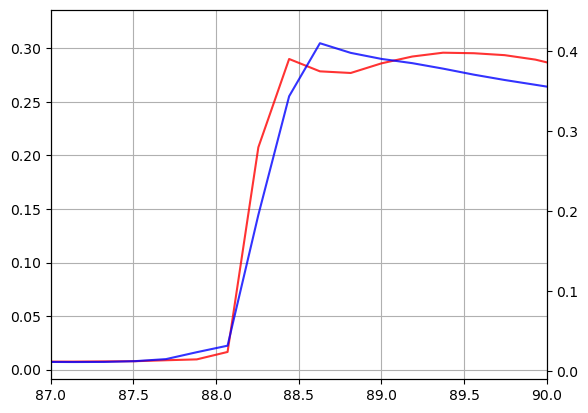

In [86]:
def plot_and_calc(run, ivl_start, ivl_end):
    d = meas[run]
    sampling_period_ns = 1000 / 168 / 32
    t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))
    fig, ax = plt.subplots()
    ax.grid()
    ax.plot(t, d['adc1'], color='red', alpha=0.8)
    ax.twinx().plot(t, d['adc2'], color='blue', alpha=0.8)
    ivl = (ivl_start, ivl_end)
    ax.set_xlim(ivl)
    
    t_slice = t[(ivl[0] <= t) & (t <= ivl[1])]
    adc1_slice = d['adc1'][(ivl[0] < t) & (t < ivl[1])]
    adc2_slice = d['adc2'][(ivl[0] < t) & (t < ivl[1])]
    print(len(t_slice))
    
    def edge_process(xs, ys, color):
        y_sorted = sorted(ys)
        low = statistics.mean(y_sorted[:len(y_sorted)//5])
        high = statistics.mean(y_sorted[-len(y_sorted)//5:])
        print(low, high, len(y_sorted)//5)
        amp = high - low
        th_low = low + 0.3 * amp
        th_high = low + 0.7 * amp
    
        x_low, x_high = None, None
        for x1, x2, y1, y2 in zip(xs, xs[1:], ys, ys[1:]):
            if y1 < th_low and y2 > th_low:
                x_low = x1 + (x2 - x1) * (th_low - y1) / (y2 - y1)
            if y1 < th_high and y2 > th_high:
                x_high = x1 + (x2 - x1) * (th_high - y1) / (y2 - y1)
        #ax.axvline(x_low, color=color)
        #ax.axvline(x_high, color=color)
        print(f'Rise time t_r = {x_high - x_low:.3f} ns')
    
    edge_process(t_slice, adc1_slice, 'red')
    edge_process(t_slice, adc2_slice, 'blue')

plot_and_calc('pi3hdx_clipline_risetime_new', 87, 90)

43
0.906128168106079 1.3394430796305337 8
Rise time t_r = 0.913 ns
1.3725679278373717 1.786827564239502 8
Rise time t_r = 0.937 ns


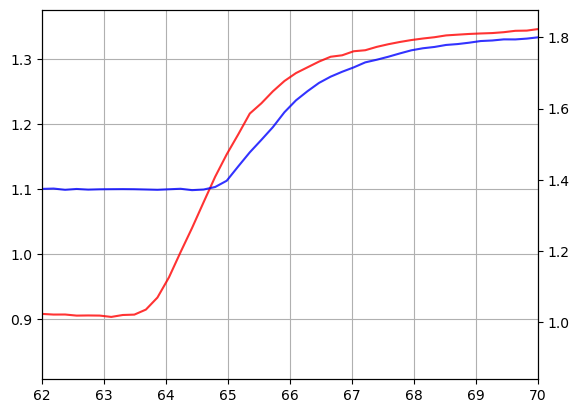

In [59]:
plot_and_calc('max3748_open', 62, 70)

53
1.6280909729003905 1.9056838989257812 10
Rise time t_r = 0.752 ns
1.5605734920501708 1.8225860595703125 10
Rise time t_r = 0.969 ns


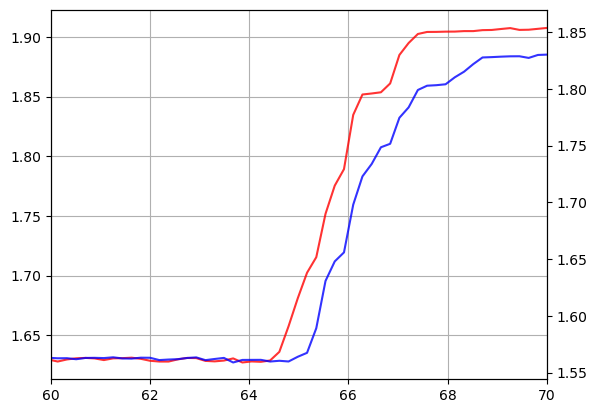

In [61]:
plot_and_calc('tdp0604_open', 60, 70)

27
1.4961741828918456 2.471108055114746 5
Rise time t_r = 0.488 ns
1.1052445793151855 2.219084692001343 5
Rise time t_r = 0.488 ns


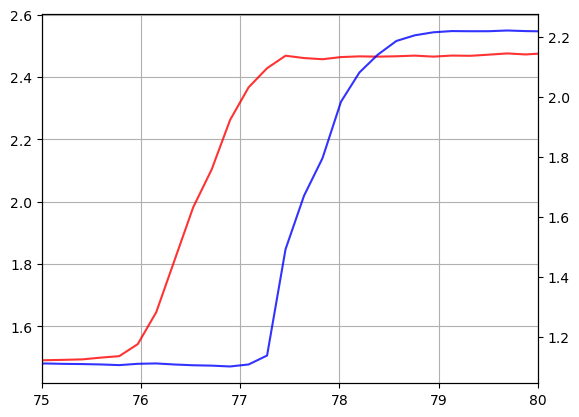

In [81]:
plot_and_calc('74lvc_new_open', 75, 80)

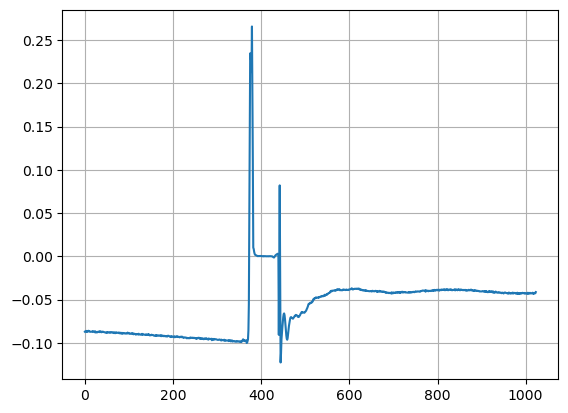

In [17]:

# just out of curiousity:
d = meas['pi3hdx_clipline_risetime']
fig, ax = plt.subplots()
ax.grid()
ax.plot(d['adc1'] - d['adc2'])